# Риск × ценность: кого удерживать

Модель оттока (`07_churn_model.ipynb`) говорит, кто уйдёт с большей вероятностью, но не говорит, сколько денег это стоит. Здесь вероятность оттока объединяется
с ценностью клиента, чтобы выбрать, кого удерживать при ограниченном бюджете. Суммы в NTD, без дисконтирования.

**Данные.** Клиенты, у которых подписка заканчивается в марте 2017 (970 960 человек): предсказания LightGBM (модель их не видела при обучении) и фактический отток.

**Ценность клиента** `V = месячная цена × A`:
- месячная цена `m`: оплата последней транзакции, приведённая к 30 дням;
- `A`: ожидаемое число месяцев с действующей подпиской за горизонт `H` (6 или 12 месяцев) для клиента, продлившего подписку. Оценивается по реальным данным: клиенты,
  у которых подписка заканчивалась в марте 2016 и которые продлили её (подписка действует в апреле 2016), и число месяцев, в которых подписка действовала у них следующие `H` месяцев
  (апрель 2016 .. март 2017 полностью наблюдается). Оценка считается по сегментам «группа тарифа × автопродление» последней транзакции.

**Ожидаемая потеря** `L = p × V`, где `p` вероятность оттока. Для денежных оценок используются вероятности, сдвинутые так, чтобы средняя вероятность равнялась фактической доле оттока марта
(исходные предсказания занижены: 6,4% при факте 9,0%); этот сдвиг справочный, в момент прогноза доля оттока будущего месяца неизвестна.

**Стратегии отбора клиентов для удержания:** случайный выбор, по риску `p`, по ценности `V`, по ожидаемой потере `L = p × V`. Верхняя граница: отбор по фактической потере (знает, кто уйдёт).

**Две оценки.**
- *По факту*: какая доля реально потерянной выручки (клиенты, которые ушли, умноженные на их `V`) оказалась среди выбранных клиентов. Допущений о воздействии не требует.
- *Экономическая*: выгода кампании `e × (сохранённая выручка) − стоимость контактов`, где `e` эффективность удержания (доля уходящих клиентов, которых удалось удержать), стоимость контакта задаётся
  долей `c` от средней месячной цены. `e` и `c` это сценарные допущения: причинный эффект удержания по этим данным оценить нельзя.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

P = "/workspace/data/processed/"
MONTH = "2017-03-01"  # месяц окончания подписки клиентов, для которых считаем отбор
REF = "2016-03-01"  # месяц, по которому оценивается A (число активных месяцев после продления)
REF_NEXT = "2016-04-01"
REF_END = {6: "2016-09-01", 12: "2017-03-01"}  # последний месяц горизонта H
SHARE = 20  # процент клиентов для оценки A
HORIZONS = [6, 12]
INK, BLUE, ORANGE, GREEN, GRAY, PINK = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98", "#CC79A7"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
con.execute(f'''
    CREATE VIEW tr AS
    SELECT
        msno,
        transaction_date AS td,
        membership_expire_date AS ex,
        is_cancel,
        payment_plan_days AS plan_days,
        is_auto_renew AS auto_renew
    FROM '{P}transactions.parquet'
''')
con.execute(f'''
    CREATE VIEW act AS
    SELECT *
    FROM '{P}active_months.parquet'
''')


def plan_group(days: float) -> str:
    '''Относит длину тарифа в днях к группе.

    Args:
        days (float): длина тарифа в днях.

    Returns:
        str: название группы.
    '''
    if pd.isna(days):
        return "нет данных"
    if days < 30:
        return "до 29 дней"
    if days <= 31:
        return "30-31 день"
    if days < 180:
        return "32-179 дней"
    return "180+ дней"

## 1. Ожидаемое число активных месяцев после продления (A)
Выборка клиентов по хешу `msno` (доля `SHARE`). Кандидаты: последняя транзакция до 1 марта 2016 заканчивается в марте 2016 (так же определяется состояние подписки на момент прогноза
в `05_churn_features.py`). Продлил: подписка действует в апреле 2016. `A_H`: число месяцев с действующей подпиской в окне из `H` месяцев после апреля 2016 включительно.
Если сегмент меньше 200 клиентов, берётся среднее по всем продлившим.

In [2]:
ref = con.sql(f'''
    WITH cand AS (
        SELECT
            msno,
            plan_days,
            auto_renew
        FROM (
            SELECT
                msno,
                plan_days,
                auto_renew,
                ex,
                row_number() OVER (PARTITION BY msno ORDER BY td DESC, ex DESC, is_cancel DESC) AS rn
            FROM tr
            WHERE td < DATE '{REF}'
                AND hash(msno) % 100 < {SHARE}
        )
        WHERE rn = 1
            AND ex >= DATE '{REF}'
            AND ex < DATE '{REF_NEXT}'
    ),
    renewed AS (
        SELECT cand.*
        FROM cand
        JOIN act ON act.msno = cand.msno
            AND act.month = DATE '{REF_NEXT}'
    )
    SELECT
        renewed.plan_days,
        renewed.auto_renew,
        count(*) FILTER (WHERE act.month BETWEEN DATE '{REF_NEXT}' AND DATE '{REF_END[6]}') AS a6,
        count(*) FILTER (WHERE act.month BETWEEN DATE '{REF_NEXT}' AND DATE '{REF_END[12]}') AS a12,
        renewed.msno
    FROM renewed
    JOIN act ON act.msno = renewed.msno
    GROUP BY renewed.msno, renewed.plan_days, renewed.auto_renew
''').df()
ref["plan_g"] = ref.plan_days.map(plan_group)
print("продливших клиентов в оценке:", len(ref))
k_tab = ref.groupby(["plan_g", "auto_renew"]).agg(клиентов=("msno", "size"), A6=("a6", "mean"), A12=("a12", "mean")).round(2)
overall = ref[["a6", "a12"]].mean()
print("среднее по всем продлившим: A6 =", round(overall.a6, 2), " A12 =", round(overall.a12, 2))
k_tab

продливших клиентов в оценке: 135706
среднее по всем продлившим: A6 = 5.69  A12 = 10.93


клиентов    A6    A12
plan_g      auto_renew                       
180+ дней   0               1880  5.84  11.26
30-31 день  0              16152  5.15   9.50
            1             116563  5.77  11.14
32-179 дней 0                220  5.37   9.77
до 29 дней  0                891  4.73   8.80

## 2. Клиенты марта 2017: цена, ценность, ожидаемая потеря
Месячная цена `m`: оплата последней транзакции, умноженная на 30 и делённая на длину тарифа; для тарифа 0 дней (оплата около 160 NTD, смысл тарифа в описании данных неясен)
берётся сама оплата; для нулевой оплаты (пробный период) средний платёж клиента; если и его нет, медиана по клиентам. Значения обрезаются по квантилям 0,1% и 99,9%.
`A_H` подставляется по сегменту клиента (группа тарифа последней транзакции и автопродление).

In [3]:
cl = con.sql(f'''
    SELECT
        f.msno,
        f.last_plan_days,
        f.last_paid,
        f.avg_paid,
        coalesce(f.last_auto_renew, 0) AS auto_renew,
        f.has_profile,
        p.is_churn,
        p.p_lgbm,
        p.p_lgbm_shifted
    FROM '{P}churn_features.parquet' f
    JOIN '{P}churn_predictions.parquet' p USING (msno)
    WHERE f.expire_month = DATE '{MONTH}'
''').df()
print("клиентов:", len(cl), " доля оттока:", round(cl.is_churn.mean(), 4), " среднее p:", round(cl.p_lgbm.mean(), 4), " среднее p со сдвигом:", round(cl.p_lgbm_shifted.mean(), 4))

paid, days, avg = (cl[c].to_numpy(dtype=float, na_value=np.nan) for c in ["last_paid", "last_plan_days", "avg_paid"])
with np.errstate(invalid="ignore", divide="ignore"):
    cond = [(days > 0) & (paid > 0), (days <= 0) & (paid > 0), avg > 0]
    m_raw = np.select(cond, [paid * 30 / days, paid, avg], default=np.nan)
cl["price_source"] = np.select(cond, ["оплата, приведённая к 30 дням", "оплата (тариф 0 дней)", "средний платёж"], default="медиана")
cl["m"] = m_raw
cl["m"] = cl.m.fillna(cl.m.median()).clip(cl.m.quantile(0.001), cl.m.quantile(0.999))
cl["plan_g"] = cl.last_plan_days.map(plan_group)
print(cl.price_source.value_counts().to_string())
print("месячная цена: среднее", round(cl.m.mean(), 1), "медиана", round(cl.m.median(), 1), "5%", round(cl.m.quantile(0.05), 1), "95%", round(cl.m.quantile(0.95), 1))

k_flat = ref.groupby(["plan_g", "auto_renew"]).agg(n=("msno", "size"), a6=("a6", "mean"), a12=("a12", "mean")).reset_index()
k_flat = k_flat[k_flat.n >= 200]
cl = cl.merge(k_flat[["plan_g", "auto_renew", "a6", "a12"]], on=["plan_g", "auto_renew"], how="left")
cl["a6"] = cl.a6.fillna(overall.a6)
cl["a12"] = cl.a12.fillna(overall.a12)
for h in HORIZONS:
    cl[f"V{h}"] = cl.m * cl[f"a{h}"]
    cl[f"L{h}"] = cl.p_lgbm_shifted * cl[f"V{h}"]
pd.DataFrame({
    f"H={h}": {
        "средняя ценность V": cl[f"V{h}"].mean(), "суммарная ценность V, млн": cl[f"V{h}"].sum() / 1e6,
        "фактически потеряно, млн": (cl.is_churn * cl[f"V{h}"]).sum() / 1e6,
        "ожидаемая потеря по модели, млн": cl[f"L{h}"].sum() / 1e6,
    } for h in HORIZONS
}).round(1)

клиентов: 970960  доля оттока: 0.0899  среднее p: 0.0639  среднее p со сдвигом: 0.0899


price_source
оплата, приведённая к 30 дням    963567
медиана                            3969
средний платёж                     3418
оплата (тариф 0 дней)                 6
месячная цена: среднее 130.3 медиана 149.0 5% 99.0 95% 180.0


,H=6,H=12
средняя ценность V,742.6,1426.1
"суммарная ценность V, млн",721.0,1384.7
"фактически потеряно, млн",68.3,129.6
"ожидаемая потеря по модели, млн",68.8,130.1


## 3. Сколько потерянной выручки находит каждое правило отбора
Клиенты упорядочиваются по оценке правила; для доли клиентов `k` (бюджета) считается, какая доля фактически потерянной выручки (`is_churn × V`) оказалась среди первых `k`.
Случайный выбор даёт `k`. Верхняя граница: упорядочивание по самой потере. Основной горизонт `H = 12`.

In [4]:
H = 12
V = cl[f"V{H}"].to_numpy()
lost = cl.is_churn.to_numpy() * V
n = len(cl)
scores = {
    "случайный выбор": None,
    "по риску p": cl.p_lgbm_shifted.to_numpy(),
    "по ценности V": V,
    "по ожидаемой потере L = p × V": cl[f"L{H}"].to_numpy(),
    "верхняя граница (знает, кто уйдёт)": lost,
}


def capture(score: np.ndarray | None, lost_arr: np.ndarray) -> np.ndarray:
    '''Считает долю потерянной выручки, найденную при отборе по убыванию оценки.

    Args:
        score (np.ndarray | None): оценка правила отбора; None для случайного выбора.
        lost_arr (np.ndarray): фактическая потеря выручки по клиентам.

    Returns:
        np.ndarray: для каждого k от 1 до n доля потерянной выручки среди первых k клиентов.
    '''
    if score is None:
        return np.arange(1, len(lost_arr) + 1) / len(lost_arr)
    order = np.argsort(-score, kind="stable")
    return np.cumsum(lost_arr[order]) / lost_arr.sum()


curves = {name: capture(s, lost) for name, s in scores.items()}
ks = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30]
cap_table = pd.DataFrame({name: [c[int(k * n) - 1] for k in ks] for name, c in curves.items()}, index=[f"{int(100 * k)}%" for k in ks])
print("Доля фактически потерянной выручки среди выбранных клиентов (H = 12)")
(100 * cap_table).round(1)

Доля фактически потерянной выручки среди выбранных клиентов (H = 12)


,случайный выбор,по риску p,по ценности V,по ожидаемой потере L = p × V,"верхняя граница (знает, кто уйдёт)"
1%,1.0,9.9,1.1,10.4,13.7
2%,2.0,18.4,2.1,18.3,26.3
5%,5.0,39.4,5.2,39.5,62.0
10%,10.0,59.4,19.5,59.6,100.0
20%,20.0,73.7,26.4,73.9,100.0
30%,30.0,79.8,33.3,80.0,100.0


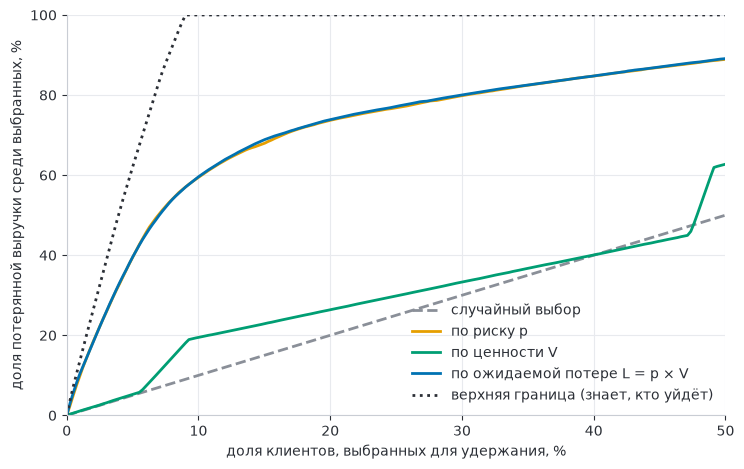

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
grid = np.linspace(0, n - 1, 400).astype(int)
styles = {
    "случайный выбор": (GRAY, "--"), "по риску p": (ORANGE, "-"), "по ценности V": (GREEN, "-"),
    "по ожидаемой потере L = p × V": (BLUE, "-"), "верхняя граница (знает, кто уйдёт)": (INK, ":"),
}
for name, c in curves.items():
    color, ls = styles[name]
    ax.plot(100 * (grid + 1) / n, 100 * c[grid], color=color, ls=ls, lw=2, label=name)
ax.set_xlabel("доля клиентов, выбранных для удержания, %")
ax.set_ylabel("доля потерянной выручки среди выбранных, %")
ax.set_xlim(0, 50)
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower right")
plt.show()

## 4. Экономика кампании
Для клиента, к которому применяется удержание, ожидаемая выгода равна `e × L − c × m̄`: сохранённая доля ожидаемой потери минус стоимость контакта (`m̄` средняя месячная цена).
Отбор по порогу: контактировать клиента стоит, если `e × L > c × m̄`. Таблица показывает для сочетаний `e` (эффективность) и `c` (стоимость контакта в долях месячной цены):
какую долю клиентов выгодно контактировать, ожидаемую по модели выгоду (по `L`) и выгоду по факту (по реально потерянной выручке уходящих клиентов, из них удерживается доля `e`).
Для сравнения: выгода по факту при том же числе контактов, но отборе по риску.

In [6]:
def campaign_table(h: int) -> pd.DataFrame:
    '''Считает выгоду кампании по порогу для сетки эффективности и стоимости контакта.

    Args:
        h (int): горизонт ценности в месяцах (6 или 12).

    Returns:
        pd.DataFrame: по сочетанию (e, c): доля контактируемых клиентов, ожидаемая выгода по модели,
            выгода по факту при отборе по L, выгода по факту при том же числе контактов и отборе по риску, млн NTD.
    '''
    v = cl[f"V{h}"].to_numpy()
    l_exp = cl[f"L{h}"].to_numpy()
    lost_h = cl.is_churn.to_numpy() * v
    p = cl.p_lgbm_shifted.to_numpy()
    m_bar = cl.m.mean()
    by_risk = np.argsort(-p, kind="stable")
    rows = []
    for e in [0.05, 0.10, 0.20]:
        for c in [0.05, 0.10, 0.20]:
            cost = c * m_bar
            sel = e * l_exp > cost
            n_sel = int(sel.sum())
            rows.append({
                "e": e, "c": c, "контактируем, % клиентов": 100 * n_sel / n,
                "ожидаемая выгода (модель), млн": (e * l_exp[sel] - cost).sum() / 1e6,
                "выгода по факту, отбор по L, млн": (e * lost_h[sel] - cost).sum() / 1e6,
                "выгода по факту, отбор по риску, млн": (e * lost_h[by_risk[:n_sel]] - cost).sum() / 1e6,
            })
    return pd.DataFrame(rows).set_index(["e", "c"]).round(2)


print("H = 12; стоимость контакта c × средняя месячная цена", round(cl.m.mean(), 1), "NTD")
campaign_table(12)

H = 12; стоимость контакта c × средняя месячная цена 130.3 NTD


контактируем, % клиентов  ожидаемая выгода (модель), млн  \
e    c                                                                
0.05 0.05                     19.01                            3.79   
     0.10                     13.09                            2.82   
     0.20                      8.08                            1.53   
0.10 0.05                     32.77                            9.09   
     0.10                     19.01                            7.58   
     0.20                     13.09                            5.64   
0.20 0.05                     57.06                           21.00   
     0.10                     32.77                           18.18   
     0.20                     19.01                           15.16   

           выгода по факту, отбор по L, млн  \
e    c                                        
0.05 0.05                              3.53   
     0.10                              2.61   
     0.20                              1.46   
0.10 0.05                              8.49   
     0.10                              7.06   
     0.20                              5.22   
0.20 0.05                             20.20   
     0.10                             16.98   
     0.20                             14.12   

           выгода по факту, отбор по риску, млн  
e    c                                           
0.05 0.05                                  3.52  
     0.10                                  2.59  
     0.20                                  1.47  
0.10 0.05                                  8.46  
     0.10                                  7.04  
     0.20                                  5.18  
0.20 0.05                                 20.15  
     0.10                                 16.93  
     0.20                                 14.08

In [7]:
print("H = 6")
campaign_table(6)

H = 6


контактируем, % клиентов  ожидаемая выгода (модель), млн  \
e    c                                                                
0.05 0.05                     13.49                            1.56   
     0.10                      8.56                            0.88   
     0.20                      2.81                            0.15   
0.10 0.05                     19.36                            4.11   
     0.10                     13.49                            3.12   
     0.20                      8.56                            1.76   
0.20 0.05                     34.18                            9.78   
     0.10                     19.36                            8.22   
     0.20                     13.49                            6.24   

           выгода по факту, отбор по L, млн  \
e    c                                        
0.05 0.05                              1.44   
     0.10                              0.83   
     0.20                              0.11   
0.10 0.05                              3.82   
     0.10                              2.87   
     0.20                              1.66   
0.20 0.05                              9.10   
     0.10                              7.64   
     0.20                              5.74   

           выгода по факту, отбор по риску, млн  
e    c                                           
0.05 0.05                                  1.42  
     0.10                                  0.83  
     0.20                                  0.12  
0.10 0.05                                  3.81  
     0.10                                  2.85  
     0.20                                  1.67  
0.20 0.05                                  9.09  
     0.10                                  7.61  
     0.20                                  5.70

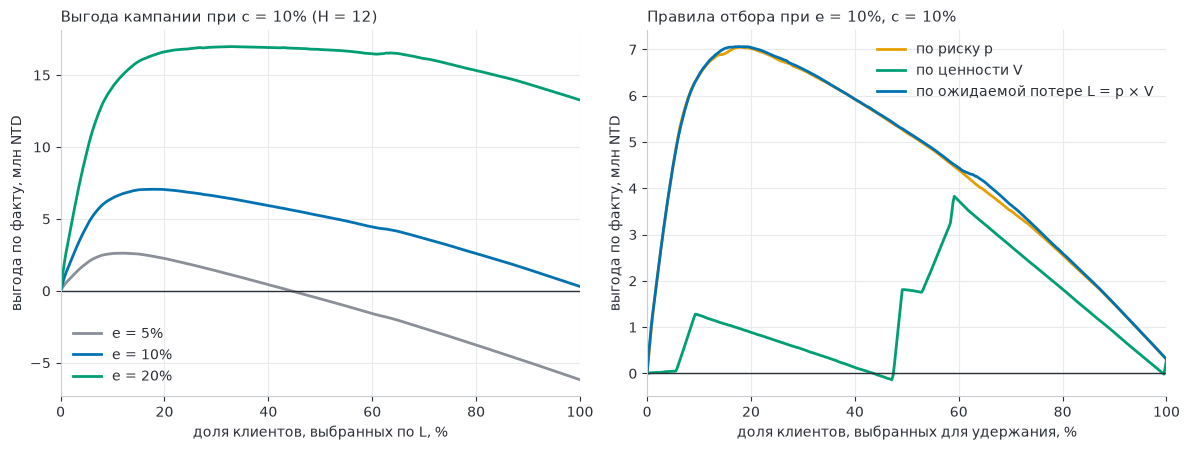

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
m_bar = cl.m.mean()
c = 0.10
cost_curve = c * m_bar * (grid + 1)  # стоимость контактов при отборе первых k клиентов
ax = axes[0]
for e, color in [(0.05, GRAY), (0.10, BLUE), (0.20, GREEN)]:
    gain = e * curves["по ожидаемой потере L = p × V"][grid] * lost.sum() - cost_curve
    ax.plot(100 * (grid + 1) / n, gain / 1e6, color=color, lw=2, label=f"e = {int(100 * e)}%")
ax.axhline(0, color=INK, lw=1)
ax.set_xlim(0, 100)
ax.set_xlabel("доля клиентов, выбранных по L, %")
ax.set_ylabel("выгода по факту, млн NTD")
ax.set_title("Выгода кампании при c = 10% (H = 12)", loc="left", fontsize=11)
ax.legend(frameon=False)

ax = axes[1]
e = 0.10
for name, color in [("по риску p", ORANGE), ("по ценности V", GREEN), ("по ожидаемой потере L = p × V", BLUE)]:
    gain = e * curves[name][grid] * lost.sum() - cost_curve
    ax.plot(100 * (grid + 1) / n, gain / 1e6, color=color, lw=2, label=name)
ax.axhline(0, color=INK, lw=1)
ax.set_xlim(0, 100)
ax.set_xlabel("доля клиентов, выбранных для удержания, %")
ax.set_ylabel("выгода по факту, млн NTD")
ax.set_title("Правила отбора при e = 10%, c = 10%", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Кого выбирает каждое правило
Состав 10% клиентов, выбранных каждым правилом: доля клиентов с автопродлением, средняя месячная цена и средняя ценность `V`, фактическая доля оттока среди выбранных.

In [9]:
rows = {}
top = int(0.10 * n)
for name, s in scores.items():
    if s is None:
        sel = np.random.default_rng(42).choice(n, top, replace=False)
    else:
        sel = np.argsort(-s, kind="stable")[:top]
    g = cl.iloc[sel]
    rows[name] = {
        "доля с автопродлением, %": 100 * g.auto_renew.mean(), "средняя цена m, NTD": g.m.mean(),
        "средняя ценность V, NTD": g[f"V{H}"].mean(), "фактический отток, %": 100 * g.is_churn.mean(),
    }
pd.DataFrame(rows).T.round(1)

,"доля с автопродлением, %","средняя цена m, NTD","средняя ценность V, NTD","фактический отток, %"
случайный выбор,88.0,130.4,1427.0,9.1
по риску p,13.7,149.3,1494.3,54.2
по ценности V,64.4,177.4,1871.7,14.5
по ожидаемой потере L = p × V,14.1,150.7,1507.9,54.1
"верхняя граница (знает, кто уйдёт)",49.1,140.3,1477.8,89.9


## 6. Где сосредоточена потеря
Для групп клиентов: доля клиентов, фактический отток, средняя месячная цена, доля ожидаемой потери по модели и доля фактически потерянной выручки (H = 12).

In [10]:
cl["profile_g"] = cl.has_profile.map({1: "есть профиль", 0: "нет профиля"})
cl["auto_g"] = cl.auto_renew.map({1: "автопродление", 0: "без автопродления"})
cl["lost"] = lost
parts = []
for col in ["auto_g", "plan_g", "profile_g"]:
    g = cl.groupby(col).agg(
        доля_клиентов=("msno", lambda s: 100 * len(s) / n), отток=("is_churn", lambda s: 100 * s.mean()),
        цена=("m", "mean"), доля_L=(f"L{H}", lambda s: 100 * s.sum() / cl[f"L{H}"].sum()),
        доля_факт_потери=("lost", lambda s: 100 * s.sum() / lost.sum()),
    )
    g.index = [f"{col.split('_')[0]}: {i}" for i in g.index]
    parts.append(g)
pd.concat(parts).round(1).rename(columns={
    "доля_клиентов": "клиентов, %", "отток": "фактический отток, %", "цена": "средняя цена m, NTD",
    "доля_L": "доля ожидаемой потери, %", "доля_факт_потери": "доля фактической потери, %",
})

,"клиентов, %","фактический отток, %","средняя цена m, NTD","доля ожидаемой потери, %","доля фактической потери, %"
auto: автопродление,88.0,4.5,127.2,42.3,45.1
auto: без автопродления,12.0,41.7,153.7,57.7,54.9
plan: 180+ дней,1.8,86.4,125.5,12.3,16.6
plan: 30-31 день,97.1,6.8,130.3,80.4,75.1
plan: 32-179 дней,0.6,71.7,133.9,3.7,4.3
plan: до 29 дней,0.2,91.3,154.4,2.1,2.3
plan: нет данных,0.3,54.7,149.0,1.4,1.7
profile: есть профиль,88.7,9.5,132.8,92.6,93.9
profile: нет профиля,11.3,5.3,111.0,7.4,6.1


## Выводы
- **Масштаб потери.** Суммарная ценность 970 960 клиентов марта на горизонте 12 месяцев около 1385 млн NTD (в среднем 1426 NTD на клиента). Фактически уходит около 9% клиентов, и их ценность составляет 129,6 млн NTD; модель со сдвигом ожидает 130,1 млн NTD, то есть в сумме оценки согласуются.
- **Ценность клиентов различается слабо.** Месячная цена у 90% клиентов лежит между 99 и 180 NTD, ожидаемое число активных месяцев после продления в сегментах составляет 8,8–11,3 из 12. Поэтому разброс вероятности оттока (от долей процента до десятков процентов) намного больше разброса ценности, и отбор по `L = p × V` почти совпадает с отбором по риску.
- **Доля найденной потери.** Среди 10% клиентов с наибольшей оценкой оказывается 59,6% фактически потерянной выручки при отборе по `L`, 59,4% при отборе по риску, 19,5% при отборе по ценности и 10% при случайном выборе (верхняя граница 100%, потому что уходит лишь около 9% клиентов). Для 5% клиентов: 39,5%, 39,4%, 5,2%, 5,0% (граница 62,0%). Отбор по одной ценности находит потерю лишь немного лучше случайного: он выбирает дорогих клиентов с автопродлением (64% выбранных), которые уходят редко.
- **Состав выбранных.** Среди 10% клиентов с наибольшим риском доля автопродлений 13,7% (в целом 88%), фактический отток 54,2%, средняя цена 149 NTD.
- **Экономика кампании (H = 12).** Выгодно контактировать клиентов, у которых `e × L` выше стоимости контакта. При e = 10% и стоимости контакта 10% месячной цены это 19% клиентов; ожидаемая выгода 7,6 млн NTD, по факту 7,1 млн NTD (около 5% от потерянных 129,6 млн). При e = 5%, c = 20% контактируется 8% клиентов, выгода 1,5 млн NTD; при e = 20%, c = 5% контактируется 57% клиентов, выгода по факту 20,2 млн NTD. Во всех рассмотренных сценариях выгода положительна, потому что стоимость контакта (5–20% месячной цены) мала по сравнению с ожидаемой потерей отобранных клиентов (у отобранных клиентов ожидаемая потеря порядка сотен NTD на клиента). На горизонте 6 месяцев выгода примерно вдвое меньше (при e = 10%, c = 10%: 2,9 млн NTD по факту).
- **Отбор по `L` против отбора по риску** при том же числе контактов даёт выгоду по факту, различающуюся менее чем на 1% (например, 7,06 и 7,04 млн NTD). Выигрыш от учёта ценности на этих данных пренебрежимо мал; он появился бы при большем разбросе ценности (например, при разных тарифных планах и ценах).
- **Где сосредоточена потеря.** Клиенты без автопродления составляют 12% и дают 54,9% фактической потери (фактический отток 41,7%, у клиентов с автопродлением 4,5%). Тариф 30–31 день: 97% клиентов и 75% потери. Клиенты с тарифом 180 дней и больше: 1,8% клиентов, отток 86% (по окончании предоплаченного срока), 16,6% потери. Клиенты без профиля: 11% клиентов, отток 5,3%.
- **Калибровка и допущения.** Предсказания сдвинуты к фактической доле оттока марта, а этот сдвиг в момент прогноза недоступен; сравнение правил по порядку клиентов от него не зависит, денежные оценки зависят. Ценность `V` это оценка по сегментам, а не наблюдаемая будущая выручка (будущее клиентов марта в данных отсутствует), и она предполагает, что поведение продливших клиентов в 2016-2017 годах такое же. Эффективность удержания `e` и стоимость контакта `c` заданы сценариями, причинный эффект по этим данным не оценивался: результаты показывают, в каких условиях кампания окупается, а не какой эффект она даст.
